<a href="https://colab.research.google.com/github/fcabralm/myhippocampus/blob/main/THBS1_Clarke_Analysis_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Thbs1 mean log2(x+1) = 0.32; genes with variance: 23673
Clarke: Thbs1 r=-0.71 (p=0.0044, n=14); whole-genome percentile 7.76% of 23673 genes; expression-matched (500 genes) 3.33%; adults only (10wk-2yr, n=8): r=-0.94, p=0.000
saved clarke_A_thbs1_by_age
saved clarke_B_genome_null

Comparison genes (Pearson r vs log10 age, n=14; BH across these genes):
               r       p  mean_log2    q_BH
gene                                      
Thbs1   -0.7101  0.0044     0.3173  0.0222
Thbs2    0.5451  0.0438     0.5947  0.1460
Sparcl1  0.8447  0.0001     9.5974  0.0014
Sparc    0.4188  0.1361     8.9936  0.3137
Tgfb1   -0.2772  0.3374     0.3948  0.4217
Gpc4    -0.3997  0.1568     2.5728  0.3137
Gpc6     0.0929  0.7521     3.3783  0.8357
Bdnf    -0.2811  0.3303     1.1053  0.4217
Wnt7a   -0.3247  0.2574     2.6610  0.4217
Chrdl1  -0.0275  0.9258     1.9289  0.9258
saved clarke_C_gene_trajectories
saved clarke_D_gene_correlations
saved clarke_E_regression
Regression (all): slope = -0.23 log2 

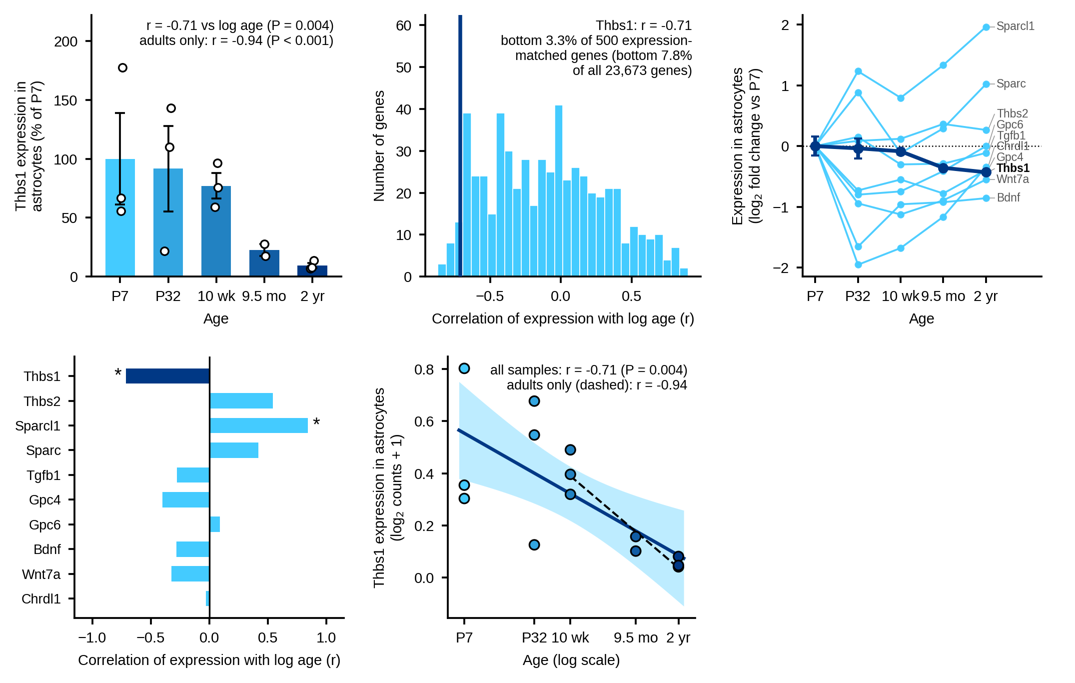

In [ ]:
# =============================================================================
# Figure 2 panels from Clarke et al. 2018 (hippocampal astrocyte TRAP-seq, Dataset S4)
#
#   clarke_A_thbs1_by_age   Thbs1 per sample across 5 ages (% of P7)
#   clarke_B_genome_null    Thbs1 age-association vs expression-matched genes
#   clarke_C_gene_trajectories  Thbs1 vs the other synaptogenic astrocyte genes (log2 FC vs P7)
#   clarke_D_gene_correlations  age correlation (r) of each of those genes
#   clarke_E_regression     Thbs1 vs log10 age, regression line with 95% CI
# Input: /content/Dataset_S4.xlsx.
# =============================================================================
import re, os, numpy as np, pandas as pd, scipy.stats as stats
import matplotlib as mpl, matplotlib.pyplot as plt

S4_PATH = "/content/Dataset_S4.xlsx"
OUTDIR = "/content/figure_panels"; os.makedirs(OUTDIR, exist_ok=True)
PANEL_W, PANEL_H = 2.4, 2.3          # inches; same for every panel (edit to fit the layout)
PANEL_LETTERS = False
GENE = "Thbs1"; N_MATCH = 500

# ---------------- style ----------------
LIGHT, DARK = "#44CBFF", "#003885"   #
def blend(t):
    a = np.array(mpl.colors.to_rgb(LIGHT)); b = np.array(mpl.colors.to_rgb(DARK)); return tuple(a + (b - a) * t)
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"], "font.size": 7,
    "axes.edgecolor": "black", "axes.linewidth": 0.9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "xtick.direction": "out", "ytick.direction": "out", "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.major.size": 3, "ytick.major.size": 3, "axes.labelsize": 7, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "savefig.dpi": 300,
})
def new_panel():
    fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H)); return fig, ax
def save(fig, name, letter=None):
    if PANEL_LETTERS and letter: fig.text(0.0, 1.0, letter, fontsize=10, fontweight="bold", va="top")
    fig.tight_layout()
    for ext in ("png", "svg", "pdf"): fig.savefig(f"{OUTDIR}/{name}.{ext}", bbox_inches="tight", facecolor="white")
    print("saved", name)
def fmtp(p): return "P < 0.001" if p < 0.001 else f"P = {p:.3f}" if p < 0.01 else f"P = {p:.2f}"

# ---------------- data ----------------
AGE_DAYS = {"P7": 7, "P32": 32, "10wk": 70, "9.5m": 289, "2yr": 730}
ORDER = ["P7", "P32", "10wk", "9.5m", "2yr"]; XLAB = ["P7", "P32", "10 wk", "9.5 mo", "2 yr"]
s4 = pd.read_excel(S4_PATH); s4 = s4.set_index(s4.columns[0])
cols, meta = [], []
for c in s4.columns:
    n = c.replace(" ", "")
    if "input" in n.lower(): continue
    a = re.search(r"(P7|P32|10wk|9\.5m|2yr)", n); r = re.search(r"rep_?(\d+)", n, re.I)
    if a and r: cols.append(c); meta.append((a.group(1), int(r.group(1))))
assert len(cols) == 14, f"expected 14 astrocyte columns, got {len(cols)}"
M = pd.DataFrame(meta, columns=["age_group", "rep"], index=cols)
M["log_age"] = np.log10(M.age_group.map(AGE_DAYS))
raw = s4[cols].astype(float)
L = np.log2(raw + 1); L = L[L.std(axis=1) > 0]            # no expression filter: Thbs1 is lowly expressed
assert GENE in L.index, "Thbs1 not found (or constant) in Dataset S4"
print(f"Thbs1 mean log2(x+1) = {L.loc[GENE].mean():.2f}; genes with variance: {len(L)}")

def corr_genes(Lsub, la):
    X = Lsub.values; xc = X - X.mean(1, keepdims=True); lc = la - la.mean()
    return pd.Series((xc @ lc) / (np.sqrt((xc ** 2).sum(1)) * np.sqrt((lc ** 2).sum())), index=Lsub.index)
r_all = corr_genes(L, M.log_age.values); r_th = r_all[GENE]; n_all = len(cols)
p_th = 2 * stats.t.sf(abs(r_th * np.sqrt((n_all - 2) / (1 - r_th ** 2))), n_all - 2)
pct = (r_all <= r_th).mean() * 100
matched = (L.mean(axis=1) - L.loc[GENE].mean()).abs().drop(GENE).nsmallest(N_MATCH).index
pct_m = (r_all[matched] <= r_th).mean() * 100
ad = M.age_group.isin(["10wk", "9.5m", "2yr"]).values
r_ad, p_ad = stats.pearsonr(M.log_age[ad], L.loc[GENE, M.index[ad]])
print(f"Clarke: Thbs1 r={r_th:.2f} (p={p_th:.4f}, n={n_all}); whole-genome percentile {pct:.2f}% of {len(r_all)} genes; "
      f"expression-matched ({N_MATCH} genes) {pct_m:.2f}%; adults only (10wk-2yr, n={ad.sum()}): r={r_ad:.2f}, p={p_ad:.3f}")
LEGEND = []

# ---------------- A: Thbs1 per sample, % of P7 (bars mean +/- SEM, open circles) ----------------
lin = (2 ** L.loc[GENE] - 1)                                   # back to linear scale
pct_p7 = lin / lin[M.index[M.age_group == "P7"]].mean() * 100
fig, ax = new_panel(); rng = np.random.default_rng(1)
for i, ag in enumerate(ORDER):
    y = pct_p7[M.index[M.age_group == ag]].values
    m, se = y.mean(), (y.std(ddof=1) / np.sqrt(len(y)) if len(y) > 1 else 0)
    ax.bar(i, m, width=.62, color=blend(i / 4), edgecolor="none", zorder=2)
    ax.errorbar(i, m, yerr=se, color="black", capsize=2.5, lw=.9, capthick=.9, zorder=3)
    ax.scatter(rng.normal(i, .06, len(y)), y, s=14, facecolor="white", edgecolor="black", linewidth=.8, zorder=4)
ax.set_xticks(range(5)); ax.set_xticklabels(XLAB); ax.set_xlim(-.6, 4.6)
ax.set_ylabel("Thbs1 expression in\nastrocytes (% of P7)"); ax.set_xlabel("Age")
top = max(pct_p7.max(), 100) * 1.25; ax.set_ylim(0, top)
ax.text(.97, .98, f"r = {r_th:.2f} vs log age ({fmtp(p_th)})\nadults only: r = {r_ad:.2f} ({fmtp(p_ad)})",
        transform=ax.transAxes, ha="right", va="top", fontsize=6.5)
save(fig, "clarke_A_thbs1_by_age", "A"); plt.close(fig)
LEGEND.append(f"Clarke_A. Thbs1 expression in hippocampal astrocytes across the lifespan (Clarke et al. 2018, TRAP-seq, mouse; 14 samples: P7, P32, 10 wk, 9.5 mo, 2 yr). Bars: mean ± SEM, circles: individual samples, expressed as % of the P7 mean (linear scale). Pearson correlation with log10(age): r = {r_th:.2f} ({fmtp(p_th)}, n = {n_all}); adult samples only (10 wk-2 yr, n = {int(ad.sum())}): r = {r_ad:.2f} ({fmtp(p_ad)}). No pairwise tests were performed. Part of the decline reflects postnatal development (P7, P32).")

# ---------------- B: Thbs1 vs expression-matched genes ----------------
fig, ax = new_panel()
ax.hist(r_all[matched].values, bins=30, color=LIGHT, edgecolor="white", linewidth=.4, zorder=2)
ymax = ax.get_ylim()[1]; ax.set_ylim(0, ymax * 1.45)
ax.axvline(r_th, color=DARK, lw=1.8, zorder=3)
ax.text(.97, .98, f"Thbs1: r = {r_th:.2f}\nbottom {pct_m:.1f}% of {N_MATCH} expression-\nmatched genes (bottom {pct:.1f}%\nof all {len(r_all):,} genes)",
        transform=ax.transAxes, ha="right", va="top", fontsize=6.5)
ax.set_xlabel("Correlation of expression with log age (r)"); ax.set_ylabel("Number of genes")
save(fig, "clarke_B_genome_null", "B"); plt.close(fig)
LEGEND.append(f"Clarke_B. Distribution of the correlation (Pearson r) between expression and log10(age) for the {N_MATCH} genes closest to Thbs1 in mean expression (bars); Thbs1 is marked by the dark line (r = {r_th:.2f}). Thbs1 lies in the lowest {pct_m:.2f}% of the matched genes and the lowest {pct:.2f}% of all {len(r_all):,} genes with non-zero variance (14 samples; no expression filter).")


# ---------------- comparison genes (the genes of the group's original bubble plot) ----------------
from matplotlib.ticker import FuncFormatter
COMP = ["Thbs1", "Thbs2", "Sparcl1", "Sparc", "Tgfb1", "Gpc4", "Gpc6", "Bdnf", "Wnt7a", "Chrdl1"]
LABEL = {g: g for g in COMP}
rows = []
for g in COMP:
    if g not in L.index:
        print(f"WARNING: {g} missing or constant in Dataset S4"); continue
    y = L.loc[g, M.index]; r, p = stats.pearsonr(M.log_age, y)
    rows.append(dict(gene=g, r=r, p=p, mean_log2=y.mean()))
G = pd.DataFrame(rows).set_index("gene")
order_p = np.argsort(G.p.values); m_ = len(G); q = np.empty(m_); prev = 1.0
for rank_i, idx in list(enumerate(order_p))[::-1]:                  # Benjamini-Hochberg over the panel genes
    prev = min(prev, G.p.values[idx] * m_ / (rank_i + 1)); q[idx] = prev
G["q_BH"] = q
print("\nComparison genes (Pearson r vs log10 age, n=14; BH across these genes):\n", G.round(4).to_string())

# ---------------- C: trajectories, log2 fold change vs P7 ----------------
fig, ax = new_panel()
p7 = M.index[M.age_group == "P7"]
ends = {}
for g in G.index:
    y = L.loc[g] - L.loc[g, p7].mean()                                  # log2 FC vs P7 mean (log2(x+1) scale)
    m = [y[M.index[M.age_group == a]].mean() for a in ORDER]
    se = [y[M.index[M.age_group == a]].std(ddof=1) / np.sqrt((M.age_group == a).sum()) for a in ORDER]
    if g == "Thbs1":
        ax.errorbar(range(5), m, yerr=se, color=DARK, lw=1.8, marker="o", ms=4, capsize=2, zorder=5)
    else:
        ax.plot(range(5), m, color=LIGHT, lw=.9, marker="o", ms=2.5, alpha=.95, zorder=3)
    ends[g] = m[-1]

# direct labels at the right end, spread so they do not overlap
yl = ax.get_ylim(); gap = (yl[1] - yl[0]) / 24
order_g = sorted(ends, key=ends.get); pos = {}; last = -1e9
for g in order_g:
    pos[g] = max(ends[g], last + gap); last = pos[g]
shift = (np.mean([pos[g] for g in order_g]) - np.mean([ends[g] for g in order_g]))
for g in order_g:
    yy = pos[g] - shift * 0
    ax.plot([4.05, 4.2], [ends[g], yy], color="#999999", lw=.4, zorder=1)
    ax.text(4.25, yy, g, fontsize=5.5, va="center", color="black" if g == "Thbs1" else "#555555", fontweight="bold" if g == "Thbs1" else "normal")
ax.axhline(0, color="black", lw=.6, ls=":", zorder=1)
ax.set_xticks(range(5)); ax.set_xticklabels(XLAB); ax.set_xlim(-.3, 5.3)
ax.set_xlabel("Age"); ax.set_ylabel("Expression in astrocytes\n(log$_2$ fold change vs P7)")
save(fig, "clarke_C_gene_trajectories", "C"); plt.close(fig)

# ---------------- D: age correlation per gene ----------------
fig, ax = new_panel(); gs = list(G.index)[::-1]
for i, g in enumerate(gs):
    ax.barh(i, G.loc[g, "r"], color=DARK if g == "Thbs1" else LIGHT, height=.62, edgecolor="none", zorder=2)
    if G.loc[g, "q_BH"] < 0.05:
        x = G.loc[g, "r"]; ax.text(x + (0.04 if x >= 0 else -0.04), i, "*", ha="left" if x >= 0 else "right", va="center", fontsize=9)
ax.axvline(0, color="black", lw=.8); ax.set_yticks(range(len(gs))); ax.set_yticklabels(gs, fontsize=6.5)
ax.set_xlim(-1.15, 1.15); ax.set_xlabel("Correlation of expression with log age (r)")
save(fig, "clarke_D_gene_correlations", "D"); plt.close(fig)

# ---------------- E: regression line (Thbs1 vs log10 age) with 95% CI ----------------
fig, ax = new_panel()
x = M.log_age.values; y = L.loc[GENE, M.index].values
b, a0, r_, p_, se_b = stats.linregress(x, y)
xs = np.linspace(x.min() - .05, x.max() + .05, 100); n = len(x)
resid = y - (a0 + b * x); s_e = np.sqrt((resid ** 2).sum() / (n - 2))
ci = stats.t.ppf(.975, n - 2) * s_e * np.sqrt(1 / n + (xs - x.mean()) ** 2 / ((x - x.mean()) ** 2).sum())
ax.fill_between(xs, a0 + b * xs - ci, a0 + b * xs + ci, color=LIGHT, alpha=.35, linewidth=0, zorder=1)
ax.plot(xs, a0 + b * xs, color=DARK, lw=1.6, zorder=2)
xa, ya = x[ad], y[ad]; ba, aa, *_ = stats.linregress(xa, ya); xsa = np.linspace(xa.min(), xa.max(), 50)
ax.plot(xsa, aa + ba * xsa, color="black", lw=1, ls="--", zorder=3)
ax.scatter(x, y, s=22, c=[blend(AGE_DAYS_I) for AGE_DAYS_I in [ORDER.index(a) / 4 for a in M.age_group]], edgecolor="black", linewidth=.8, zorder=4)
ax.set_xticks([np.log10(AGE_DAYS[a]) for a in ORDER]); ax.set_xticklabels(XLAB); ax.set_xlabel("Age (log scale)")
ax.set_ylabel("Thbs1 expression in astrocytes\n(log$_2$ counts + 1)")
ax.text(.97, .97, f"all samples: r = {r_:.2f} ({fmtp(p_)})\nadults only (dashed): r = {r_ad:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=6.5)
save(fig, "clarke_E_regression", "E"); plt.close(fig)
print(f"Regression (all): slope = {b:.2f} log2 units per log10(age in days), 95% CI "
      f"{b - stats.t.ppf(.975, n-2) * se_b:.2f} to {b + stats.t.ppf(.975, n-2) * se_b:.2f}; adults: slope {ba:.2f}")
sig = ", ".join(f"{g} (r = {G.loc[g,'r']:.2f}, q = {G.loc[g,'q_BH']:.3f})" for g in G.index if G.loc[g, 'q_BH'] < .05 and g != "Thbs1") or "none"
LEGEND.append("Clarke_C. Trajectories of Thbs1 (dark blue) and nine other astrocyte synaptogenic/matricellular genes (light blue) across ages, as log2 fold change relative to the P7 mean (mean ± SEM for Thbs1; means for the other genes). Dotted line: no change.")
LEGEND.append(f"Clarke_D. Pearson correlation between expression and log10(age) for the same genes (n = 14 samples). Asterisk: Benjamini-Hochberg q < 0.05 across the ten genes. Genes other than Thbs1 with q < 0.05: {sig}. Genes with low expression have noisier estimates (mean log2(counts+1) of Thbs1 = {G.loc['Thbs1','mean_log2']:.1f}).")
LEGEND.append(f"Clarke_E. Thbs1 expression (log2(counts+1)) against log10(age) in the 14 astrocyte samples. Solid line: linear regression with 95% confidence band (slope {b:.2f} per log10 day, r = {r_:.2f}, {fmtp(p_)}); dashed line: regression restricted to adult samples (10 wk-2 yr; r = {r_ad:.2f}). Symbols are coloured by age group.")

open(f"{OUTDIR}/figure_legend_draft.txt", "w").write("\n\n".join(LEGEND)); print("\n".join(LEGEND))
from PIL import Image
ims = [Image.open(f"{OUTDIR}/{n}.png") for n in ["clarke_A_thbs1_by_age", "clarke_B_genome_null", "clarke_C_gene_trajectories", "clarke_D_gene_correlations", "clarke_E_regression"]]
w, h = max(i.width for i in ims), max(i.height for i in ims)
sheet = Image.new("RGB", (w * 3, h * 2), "white")
for k, im in enumerate(ims): sheet.paste(im, ((k % 3) * w, (k // 3) * h))
sheet.save(f"{OUTDIR}/preview_contact_sheet.png"); print("Panels in", OUTDIR)
try:
    from IPython.display import display; display(sheet.resize((sheet.width // 2, sheet.height // 2)))
except Exception: pass

In [ ]:
import shutil
from google.colab import files

# Compactar a pasta de figuras em um arquivo ZIP
shutil.make_archive('/content/figure_panels', 'zip', '/content/figure_panels')

# Fazer o download do arquivo ZIP gerado
files.download('/content/figure_panels.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>